# Figure S6: streamfunction in isopycnal coordinates, 8xCO2

Time-mean streamfunction on sigma_1 for (a) the collapsed and (b) the recovered state: the Atlantic streamfunction,
with the global one south of where the Atlantic region has ocean. Only the Eulerian-mean velocity is included. The y
axis is uniform in model layer index, which stretches the dense layers.

Input: `PSI_SIGMA1_POP_MOC_8x.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common
import cmocean as cm

matplotlib.rc('font', size=13)

In [2]:
ds = xr.open_dataset(common.data_path('PSI_SIGMA1_POP_MOC_8x.nc'))
sigma_tops = ds.sigma.values  # layer-top interfaces, where the streamfunction is defined
GLOBAL, ATLANTIC = 0, 1       # transport_reg indices
use_atlantic = ds.bin_area.isel(transport_reg=ATLANTIC) > 0

SLICES = [(800, 2300), (4000, int(ds.year[-1]) - common.BRANCH_YEAR)]  # years since 8xCO2, inclusive


def psi_mean(years):
    """Time-mean streamfunction [Sv] on (sigma, lat) over the inclusive range of years since 8xCO2."""
    first, last = years
    subset = ds.MOC.sel(year=slice(first + common.BRANCH_YEAR, last + common.BRANCH_YEAR))
    assert subset.sizes['year'] == last - first + 1, f'years {years} are outside the record'
    psi = subset.mean('year')
    psi = xr.where(use_atlantic, psi.isel(transport_reg=ATLANTIC), psi.isel(transport_reg=GLOBAL))
    return psi.transpose('sigma', 'lat_aux_grid')

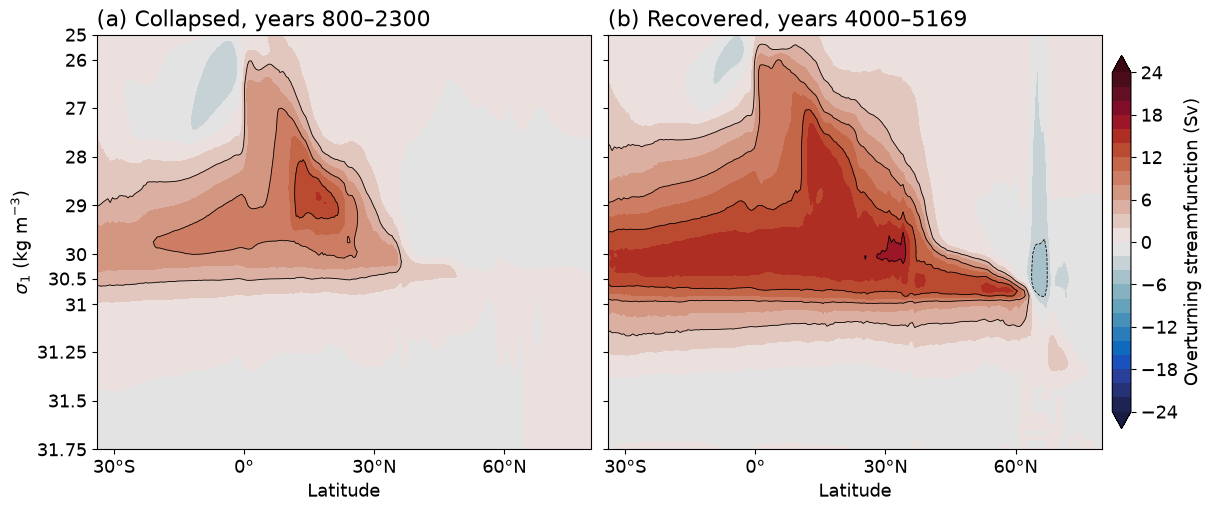

In [3]:
FILL_LEVELS = np.arange(-24, 25, 2)                                   # Sv
LINE_LEVELS = [level for level in np.arange(-24, 25, 4) if level != 0]  # the zero line only traces noise
SIGMA_LIM = (25, 31.75)
SIGMA_TICKS = [25, 26, 27, 28, 29, 30, 30.5, 31, 31.25, 31.5, 31.75]
LAT_TICKS = [-30, 0, 30, 60]
TITLES = ['(a) Collapsed, years {}–{}', '(b) Recovered, years {}–{}']


def lat_label(latitude):
    """Axis label such as 30°N."""
    return '0°' if latitude == 0 else f'{abs(latitude):g}°{"N" if latitude > 0 else "S"}'


layer_index = np.arange(sigma_tops.size, dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, constrained_layout=True)
for ax, years, title in zip(axes, SLICES, TITLES):
    psi = psi_mean(years)
    filled = ax.contourf(psi.lat_aux_grid, psi.sigma, psi, levels=FILL_LEVELS, cmap=cm.cm.balance, extend='both')
    ax.contour(psi.lat_aux_grid, psi.sigma, psi, levels=LINE_LEVELS, colors='k', linewidths=0.6)
    ax.set_yscale('function', functions=(lambda s: np.interp(s, sigma_tops, layer_index),
                                         lambda i: np.interp(i, layer_index, sigma_tops)))
    ax.set_ylim(SIGMA_LIM[1], SIGMA_LIM[0])  # dense at the bottom
    ax.set_yticks(SIGMA_TICKS)
    ax.set_yticklabels([f'{tick:g}' for tick in SIGMA_TICKS])
    ax.set_xlim((-34, 80))
    ax.set_xticks(LAT_TICKS)
    ax.set_xticklabels([lat_label(latitude) for latitude in LAT_TICKS])
    ax.set_xlabel('Latitude')
    ax.set_title(title.format(*years), loc='left')
axes[0].set_ylabel('$\\sigma_1$ (kg m$^{-3}$)')
fig.colorbar(filled, ax=axes, shrink=0.9, pad=0.01).set_label('Overturning streamfunction (Sv)')
for extension in ('png', 'pdf'):
    plt.savefig(common.figure_path(f'figS6_isopycnal_streamfunction.{extension}'), dpi=300, bbox_inches='tight')
plt.show()